# Compartmentailized DNA-based TMSE circuits in mammalian cells models

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

This notebook is an extension of [Figure2_CRISPR.ipynb]() from Simulations of a DNA-based TMSE circuits that regulate gene expression in mammalian cells from Implementing Complex Nucleic Acid Circuits in Living Cells ([Sun et al. *Science Advances* 2025](https://www.science.org/doi/10.1126/sciadv.adv6512)), to include **compartmentalization / separation of nucleus and cytosol**.

Each section illustrate how the original TMSE model can be compiled using compartments, reflecting spatial separations of environmental conditions, using BioCRNpyler's membrane component library.

Models:
* [Base Simulation](#Base-Simulation)
    * Models DNA-based TMSE circuits that regulate gene expression in mammalian cells 
* [Compartmentalized](#Compartmentalization)
    * Base + compartmentalization of transcription (nucleus) and transcription (cytosol)


## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 24 hours
timepoints = np.linspace(0,24,1001)*3600 

# Initial conditions (uM)s
dna_I1_conc = 0.25
dna_I3_conc = 0.25
dna_G_1_2_conc = 0.05
dna_G_3_2_conc = 0.05
dna_R2_conc = 0.150
dna_GFP_conc = 0.001
Cas9_conc = 1

# Input templates
IN1 = [0, 1, 0, 1]
IN3 = [0, 0, 1, 1]

idx_conditions = {'None':[[0.4,0.4,0.4], '--'],
                    'I1': [[1,0,0],'-'],
                    'I3': [[1,0.5,0],'--'],
                    'I1&I3': [[0,0,1],'--']}

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, ymin = -0.02, ymax = 100):
    fs = 22
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs, fontsize=fs)

    plt.ylim(ymin,ymax)
    plt.xlim(0,12)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)

# Base Simulation

![DNA-based TMSE circuits that regulate gene expression in mammalian cells](../schematics/Figure2_CRISPR.png)

Specific Features:
* uses base class of Mixture (a container for components, mechanisms, and parameters in a CRN model)

In [3]:
# Define initial DNA and Reporter DNA
sim_inputs = {'DNA_1': ['Input', 1], 'DNA_2': ['Input', 3],
              'DNA_3':['Gate',1,2],'DNA_4':['Gate',3,2],} # DNA
reporter = {'DNA_5':['Reporter', 2]} # DNA that is transcribed

# Components
reporter_mol = StrandExchangeMol(reporter, material_type= 'dna', transcription=True)
input_mol = StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse = TMSE([input_mol.mol,reporter_mol.rna])

# Create additional species
Cas9 = Species("Cas9")
CRISPR = Species("CRISPR")

# Add reaction for DNA rebinding
rxn_activate = Reaction.from_massaction(inputs = [Cas9, step_tmse.signals[0]],
                                        outputs = [CRISPR],
                                        k_forward = 3e-3) 

# Create activatable DNA assembly by CRISPR
hill_parameters = {"k":1.0, "n":4, "K":1, "kleak":1e-9}
# Create activatable promoter
P_activatable = ActivatablePromoter("P_activatable", activator = CRISPR, leak = True, parameters = hill_parameters)
# Create a DNA assembly "GFP"
activatable_assembly = DNAassembly(name="activatable_assembly", promoter=P_activatable, rbs="Strong", protein = 'GFP')

# Reactions
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}
# Create a transcription and translation Mechanisms
mech_tx = SimpleTranscription()
tx_mechanism= {mech_tx.mechanism_type:mech_tx}
mech_tl = SimpleTranslation()
tl_mechanism= {mech_tl.mechanism_type:mech_tl}

# Parameters
TMSE_parameters = {"kx":.05,
                   "krev":.05,
                   "krep":4e-03, 
                   "ktx":0.013, "ktl":.02,
                   } 

# Make Mixture and Compile
M_invitro = Mixture("Activatable_GFP",
                    components=[reporter_mol.mol, step_tmse, activatable_assembly],
                    parameters = TMSE_parameters,
                    mechanisms=tx_mechanism|sd_mechanisms|tl_mechanism)

# Compile the CRN with Mixture.compile_crn
CRN_invitro = M_invitro.compile_crn()

# Add CRISPR activation rxn
CRN_invitro.add_reactions([rxn_activate])

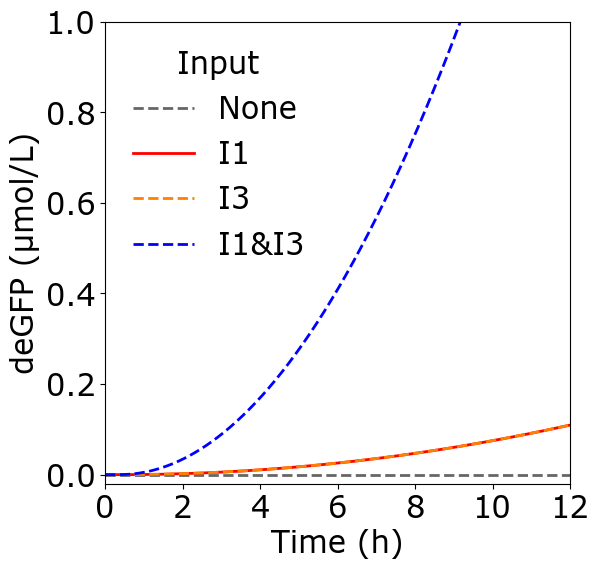

In [4]:
# Simulate
try:
    for IN1_conc, IN3_conc, key in zip(IN1, IN3, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': IN1_conc*dna_I1_conc, 'dna_Input_3': IN3_conc*dna_I3_conc,
                                      'dna_Gate_1_2':dna_G_1_2_conc, 'dna_Gate_3_2':dna_G_3_2_conc, 
                                      'dna_Reporter_2':dna_R2_conc,
                                      'dna_activatable_assembly':dna_GFP_conc,
                                      'Cas9':Cas9_conc}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_invitro.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                         initial_condition_dict = initial_concentration_dict)

        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['protein_GFP'], label = key,
                 color = idx_conditions[key][0], linewidth = 2,
                 linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='deGFP (μmol/L)',ymax = 1)    

In [5]:
# Print CRN reactions (Optional)
print(CRN_invitro.pretty_print(show_rates = True, how_attributes = True, 
                            show_materials = True, show_keys = False))

Species(N = 17) = {
rna[activatable_assembly] (@ 0),  dna[activatable_assembly] (@ 0),  rna[Signal_2] (@ 0),  rna[Reporter_2] (@ 0),  dna[Reporter_2] (@ 0),  dnarna[ReporterOut_2] (@ 0),  dna[Output_3_2] (@ 0),  dna[Output_1_2] (@ 0),  dna[Input_3] (@ 0),  dna[Input_1] (@ 0),  dna[Gate_3_2] (@ 0),  dna[Gate_1_2] (@ 0),  dna[GateOut_3_3] (@ 0),  dna[GateOut_1_1] (@ 0),  protein[GFP] (@ 0),  Cas9 (@ 0),  CRISPR (@ 0),  
}

Reactions (9) = [
0. dna[Reporter_2] --> dna[Reporter_2]+rna[Reporter_2]
 Kf=k_forward * dna_Reporter_2
  k_forward=0.013

1. dna[Gate_1_2]+dna[Input_1] <--> dna[Output_1_2]+dna[GateOut_1_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Input_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_1_1
  k_forward=0.05
  k_reverse=0.05

2. dna[Gate_3_2]+dna[Input_3] <--> dna[Output_3_2]+dna[GateOut_3_3]
 Kf=k_forward * dna_Gate_3_2 * dna_Input_3
 Kr=k_reverse * dna_Output_3_2 * dna_GateOut_3_3
  k_forward=0.05
  k_reverse=0.05

3. dna[Output_1_2]+rna[Reporter_2] --> rna[Signal_2]+dnarna[Re

## Compartmentalization

![DNA-based TMSE circuits in TxTlExtract](./../schematics/CRISPR_compartments.png)

Specific Features:
* uses base class of Mixture (a container for components, mechanisms, and parameters in a CRN model)
* compartmentalization of transcription and translation
* transport of RNA and transcriptional regulators across compartments

In [6]:
# Set a global default size for plots
plt.rcParams["figure.figsize"] = (10, 5)

In [7]:
# Define compartments
int_compartment = Compartment(name='nucleus')
ext_compartment = Compartment(name='cytosol')

In [8]:
# Nucleus environment
# Define initial DNA and Reporter DNA
sim_inputs = {'DNA_1': ['Input', 1], 'DNA_2': ['Input', 3],
              'DNA_3':['Gate',1,2],'DNA_4':['Gate',3,2],} # DNA
reporter = {'DNA_5':['Reporter', 2]} # DNA that is transcribed

# Components
step_tx = StrandExchangeMol(reporter, material_type= 'dna', transcription=True, compartment = int_compartment) #creating the nucleus dna/rna Reporter

# Nuclear pore
Npore1 = MembraneChannel(
    integral_membrane_protein = "NuclearPore1", substrate = step_tx.rna[0], 
    direction = 'Exporter', internal_compartment= int_compartment, external_compartment= ext_compartment)

# Adding additional information to created product
Npore1.product.material_type='rna'
Npore1.product.i, Npore1.product.j = 2,2


In [9]:
# Cytosol environment
input_mol = StrandExchangeMol(sim_inputs, material_type= 'dna', compartment = ext_compartment) #creating the nucleus dna/rna Reporter
step_sd = TMSE([input_mol.mol,Npore1.product], compartment = ext_compartment)

# Create additional species w/compartments identified
Cas9 = Species("Cas9", compartment=ext_compartment)
CRISPR_ext = Species("CRISPR", compartment=ext_compartment)

#CRISPR transport
Ncrisp = MembraneChannel(
    integral_membrane_protein = "Ncrisp", substrate = CRISPR_ext, 
    direction = 'Importer', internal_compartment= int_compartment, external_compartment= ext_compartment)

In [10]:
# Create activatable DNA assembly by CRISPR
hill_parameters = {"k":1.0, "n":4, "K":1, "kleak":.000000001}
# Create activatable promoter
P_activatable = ActivatablePromoter("P_activatable", activator = Ncrisp.product, leak = True, parameters = hill_parameters)
# Create a DNA assembly "GFP"
activatable_assembly = DNAassembly(name="activatable_assembly", promoter=P_activatable, rbs=None, protein = 'GFP', compartment = int_compartment)

# Transport
Npore2 = MembraneChannel(
    integral_membrane_protein = "NuclearPore2", substrate = activatable_assembly.transcript,
    direction = 'Exporter', internal_compartment= int_compartment, external_compartment= ext_compartment)
# Adding additional information to created product
Npore2.product.material_type ='rna'

# GFP rna in cytosol
rna_assembly = RNAassembly(Npore2.product, rbs="Strong", protein = 'GFP', compartment = ext_compartment)

In [11]:
# Reactions
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}
# Create a transcription and translation Mechanisms
mech_tx = SimpleTranscription()
tx_mechanism= {mech_tx.mechanism_type:mech_tx}
mech_tl = SimpleTranslation()
tl_mechanism= {mech_tl.mechanism_type:mech_tl}
# Mechanism transport
mech_transport = Facilitated_Transport_MM()
transport_mechanisms = {mech_transport.mechanism_type: mech_transport}

# Add reaction for DNA rebinding
rxn_activate = Reaction.from_massaction(inputs = [Cas9, step_sd.signals[0]],
                                outputs = [CRISPR_ext],
                                k_forward = 3) 


In [12]:
# Parameters
TMSE_parameters = {"kx":.05,
                   "krev":.05,
                   "krep":4e-03, 
                   "ktx":0.013, "ktl":.02,
                   'kb_subMC': 1e-1, 'ku_subMC': 1e-1, 'k_trnspMC': 1e-2,'ku_prodMC': 1e-1} 

# Make Mixture and Compile
M_compartments = Mixture("cell",
                         components=[step_tx.mol, activatable_assembly, # nucleus
                                     step_sd, rna_assembly, # cytosol
                                     Npore1, Ncrisp, Npore2, # transporters
                                     ],
                         parameters = TMSE_parameters,
                         mechanisms = sd_mechanisms|transport_mechanisms|tx_mechanism|tl_mechanism)

# Compile the CRN with Mixture.compile_crn
CRN_compartments = M_compartments.compile_crn()

# Add CRISPR activation rxn
CRN_compartments.add_reactions([rxn_activate])

# Print CRN reactions (Optional)
print(CRN_compartments.pretty_print(show_rates = True, how_attributes = True, 
                            show_materials = True, show_keys = False))

Species(N = 29) = {
complex[protein[NuclearPore2]:rna[activatable_assembly]] (@ 0),  complex[protein[NuclearPore2]:rna[activatable_assembly]] (@ 0),  complex[protein[NuclearPore1]:rna[Reporter_2]] (@ 0),  complex[protein[NuclearPore1]:rna[Reporter_2]] (@ 0),  rna[activatable_assembly] (@ 0),  rna[activatable_assembly] (@ 0),  dna[activatable_assembly] (@ 0),  rna[Signal_2] (@ 0),  rna[Reporter_2] (@ 0),  rna[Reporter_2] (@ 0),  dna[Reporter_2] (@ 0),  dnarna[ReporterOut_2] (@ 0),  dna[Output_3_2] (@ 0),  dna[Output_1_2] (@ 0),  protein[NuclearPore2(E, x, p, o, r, t, e)] (@ 0),  protein[NuclearPore1(E, x, p, o, r, t, e)] (@ 0),  protein[Ncrisp(I, m, p, o, r, t, e)] (@ 0),  dna[Input_3] (@ 0),  dna[Input_1] (@ 0),  dna[Gate_3_2] (@ 0),  dna[Gate_1_2] (@ 0),  dna[GateOut_3_3] (@ 0),  dna[GateOut_1_1] (@ 0),  protein[GFP] (@ 0),  Cas9 (@ 0),  complex[CRISPR:protein[Ncrisp]] (@ 0),  complex[CRISPR:protein[Ncrisp]] (@ 0),  CRISPR (@ 0),  CRISPR (@ 0),  
}

Reactions (21) = [
0. dna[Reporter_

#### Simulate

In [13]:
nucleus_species=  {'rna_Reporter_2_nucleus':['dodgerblue', 'Reporter_RNA', 'dashed' ], 'CRISPR_nucleus':['gray','CRISPR', 'dashed'], 
                   'rna_activatable_assembly_nucleus': ['rebeccapurple', 'GFP_RNA', 'solid']}
cytosol_species = {'rna_Reporter_2_cytosol':['dodgerblue', 'Reporter_RNA','dashed'], 'CRISPR_cytosol':['gray','CRISPR','dashed'], 
                   'rna_activatable_assembly_cytosol': ['rebeccapurple','GFP_RNA','solid'], 
                   'rna_Signal_2_cytosol':['coral', 'Signal_RNA','dotted'], 'protein_GFP_cytosol':['forestgreen', 'GFP_protein','solid']}

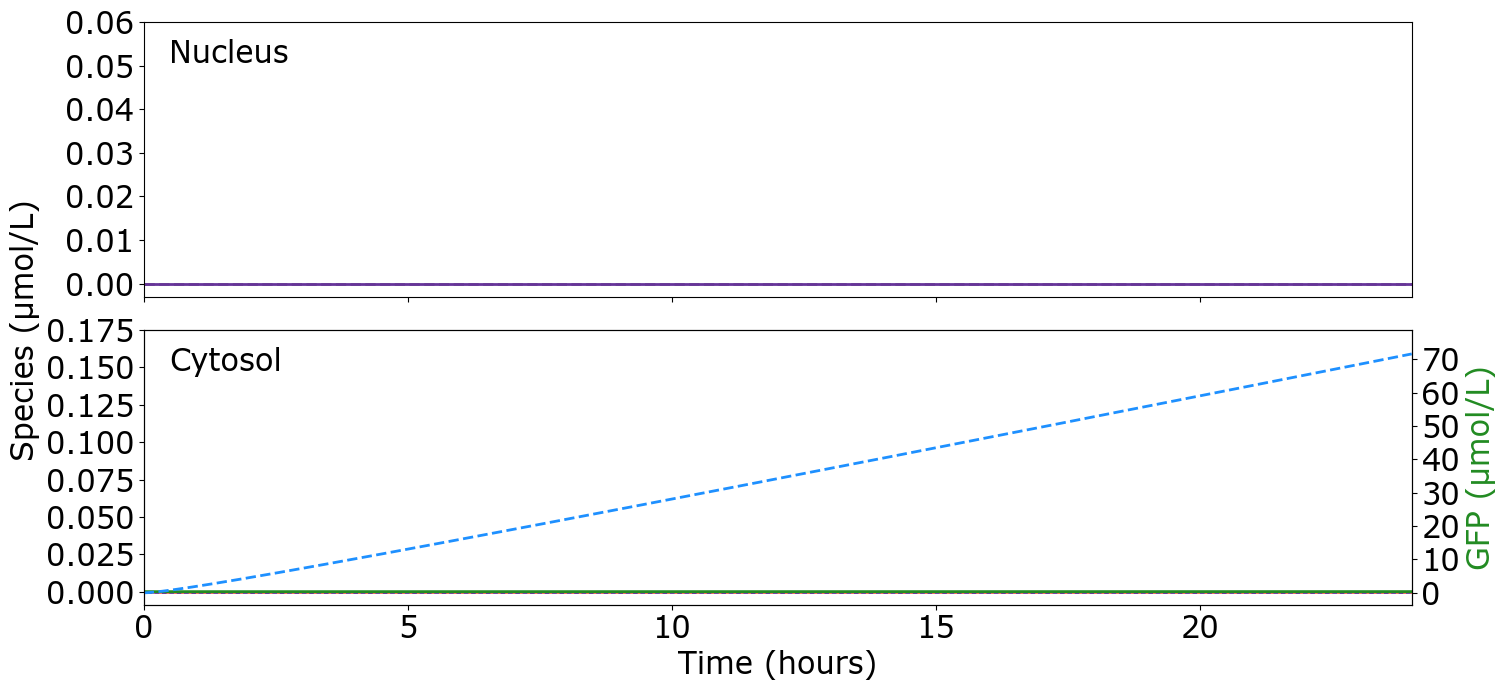

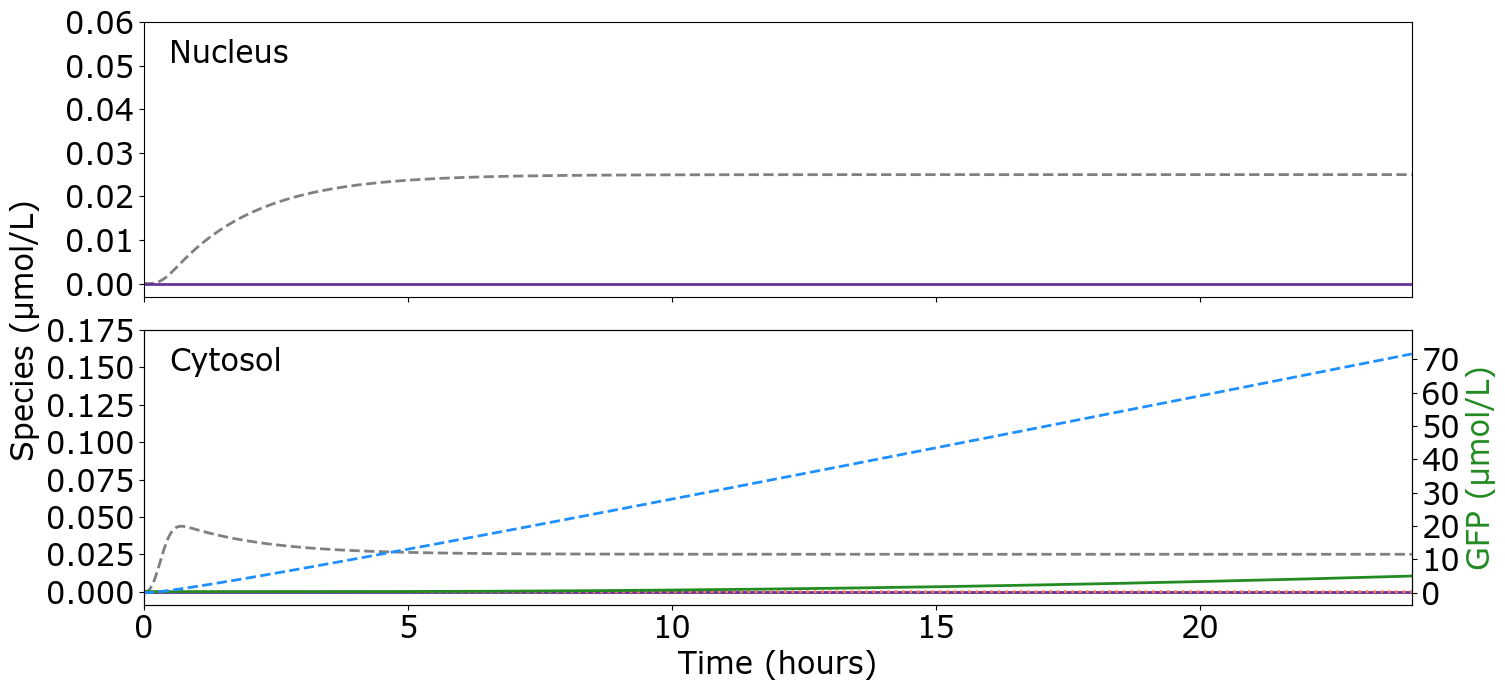

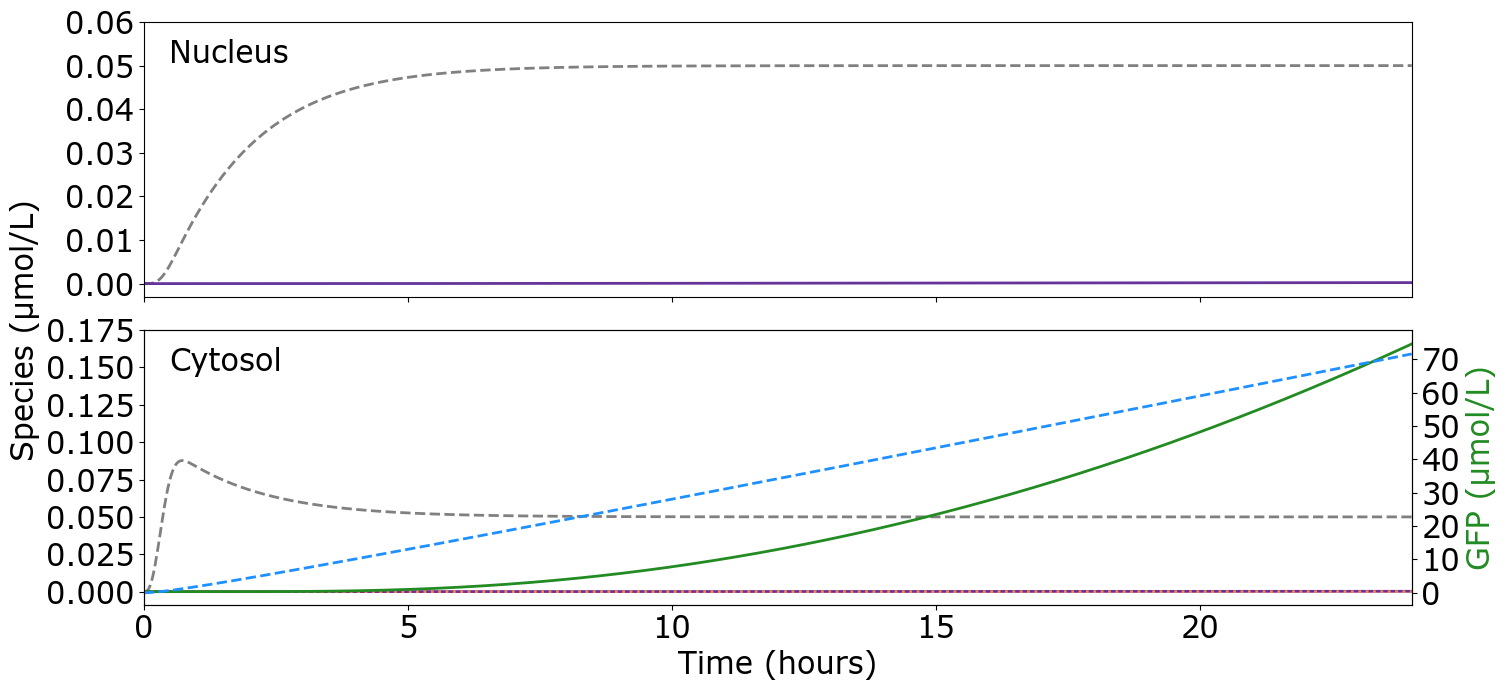

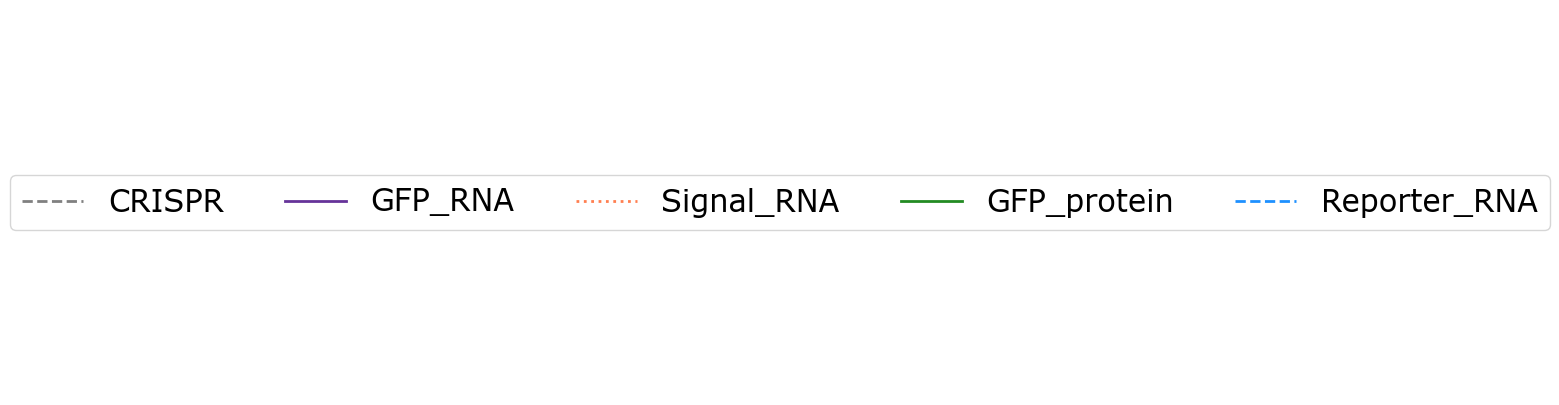

In [14]:
# Input templates
IN1 = [0, 1, 1]
IN3 = [0, 0, 1]

idx_conditions = {'None':[[0.4,0.4,0.4], '--'],
                    'I1oI3': [[1,0,0],'-'],
                    'I1nI3': [[0,0,1],'--']}

# Simulate - example for 24 hours
timepoints = np.linspace(0,24,1001)*3600 

try:
    # from mpl_axes_aligner import align
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    
    for IN1_conc, IN3_conc, key in zip(IN1, IN3, idx_conditions.keys()):
        # Create an initial condition
        initial_concentration_dict = {
            'protein_NuclearPore1_E_x_p_o_r_t_e': .1, 'protein_Ncrisp_I_m_p_o_r_t_e': .01,'protein_NuclearPore2_E_x_p_o_r_t_e': .1, # transporters
            'dna_Input_1_cytosol': IN1_conc*dna_I1_conc, 'dna_Input_3_cytosol': IN3_conc*dna_I3_conc,
            'dna_Gate_1_2_cytosol':dna_G_1_2_conc, 'dna_Gate_3_2_cytosol':dna_G_3_2_conc,
            'dna_Reporter_2_nucleus':dna_R2_conc,
            'dna_activatable_assembly_nucleus':dna_GFP_conc,
            'Cas9_cytosol':Cas9_conc*2
            }
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_compartments.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                      initial_condition_dict = initial_concentration_dict)

        fig = plt.figure(figsize=(15.1575, 7))  # Width set to match letter-size paper width (inches)
        gs = GridSpec(2, 1, figure=fig, height_ratios=[1, 1])  # Equal heights for both subplots

        ax1 = fig.add_subplot(gs[0])
        ax2 = fig.add_subplot(gs[1], sharex=ax1)

        # Create twin y-axes for Reporter data
        # ax1_rep = ax1.twinx()
        ax2_rep = ax2.twinx()

        time = R['time'] / 3600

        def plot_compartment(compartment, dict_specs, ax, ax_rep=None):
            primary_max = -float('inf')
            reporter_max = -float('inf')

            # Determine data ranges for alignment
            for key in dict_specs.keys():
                if 'Reporter' in key:
                    data = R[key]
                    reporter_max = max(reporter_max, data.max(), 0)
                    if ax_rep is not None:
                        ax_rep.plot(time, data, label=dict_specs[key][1],
                                    color=dict_specs[key][0], linewidth=2, linestyle=dict_specs[key][2])
                else:
                    data = R[key]
                    primary_max = max(primary_max, data.max(), 0)
                    ax.plot(time, data, label=dict_specs[key][1],
                            color=dict_specs[key][0], linewidth=2, linestyle=dict_specs[key][2])

            # Annotate compartment plot
            ax.text(0.02, 0.85, compartment,
                    fontsize=22, fontstyle='italic',
                    fontweight='light', fontfamily='sans-serif',
                    transform=ax.transAxes)

            return primary_max, reporter_max

        # Plot Nucleus data on the upper subplot (ax1)
        primary_max_nuc, reporter_max_nuc = plot_compartment('Nucleus', nucleus_species, ax1,)

        # Plot Cytosol data on the lower subplot (ax2)
        primary_max_cyt, reporter_max_cyt = plot_compartment('Cytosol', cytosol_species, ax2, ax2_rep)

        # Set y-limits based on determined ranges
        ax1.set_ylim(-0.003, 0.06)  # Add some margin
        ax2.set_ylim(-0.00875, 0.175)
        ax2_rep.set_ylim(reporter_max_cyt * -0.05, reporter_max_cyt * 1.1)

        ax1.set_xlim(0, 24)  # Add some margin
        ax2.set_xlim(0, 24)

        # Change the size of tick labels
        for tick in ax2.get_xticklabels():
            tick.set_fontsize(22)
        for tick in ax1.get_yticklabels():
            tick.set_fontsize(22)
        for tick in ax2_rep.get_yticklabels():
            tick.set_fontsize(22)
        for tick in ax2.get_yticklabels():
            tick.set_fontsize(22)

        # Set shared x-label for both plots
        plt.setp(ax1.get_xticklabels(), visible=False)  # Hide x-ticks for top plot
        ax2.set_xlabel('Time (hours)', fontsize=22)

        # Set y-axis labels for the primary and secondary axes 
        ax2.set_ylabel('Species (μmol/L)', color='black', fontsize=22)
        y_label = ax2.get_yaxis().get_label()
        y_label.set_position((0, 1))  

        ax2_rep.set_ylabel('GFP (μmol/L)', color='forestgreen', fontsize=22)

        plt.tight_layout()
        plt.show()

        fig.savefig(f'{figs_dir}/SI_compartmentalization_{key}.svg')
        # Create a separate figure with only the legend, removing duplicates and distinguishing colors
        
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")


def collect_handles_labels(ax):
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

handles, labels = [], []

collect_handles_labels(ax1)
collect_handles_labels(ax2)
# collect_handles_labels(ax1_rep)
collect_handles_labels(ax2_rep)

# Create a single-line legend with combined handles and labels
fig_legend, ax_legend = plt.subplots()
ax_legend.axis('off')
ax_legend.legend(handles, labels, loc='center', ncol=len(labels), bbox_to_anchor=(0.5, 0.5), fontsize=22)
plt.show()
fig_legend.savefig(f'{figs_dir}/SI_compartmentalization_legend.svg')

# Computing environment

In [15]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

